## 실험 1-1: Actor-Critic (Seed 42)

### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- 학습 2,000에피소드
- 랜덤 시드 42

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_seed42_checkpoints/actor_critic_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -294.49 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -260.94 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -235.74 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -222.75 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -217.33 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -211.64 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -209.11 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -209.03 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -209.32 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -206.92 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_seed42_checkpoints/actor_critic_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -207.27 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -205.08 | Success: 0 | Timeout: 

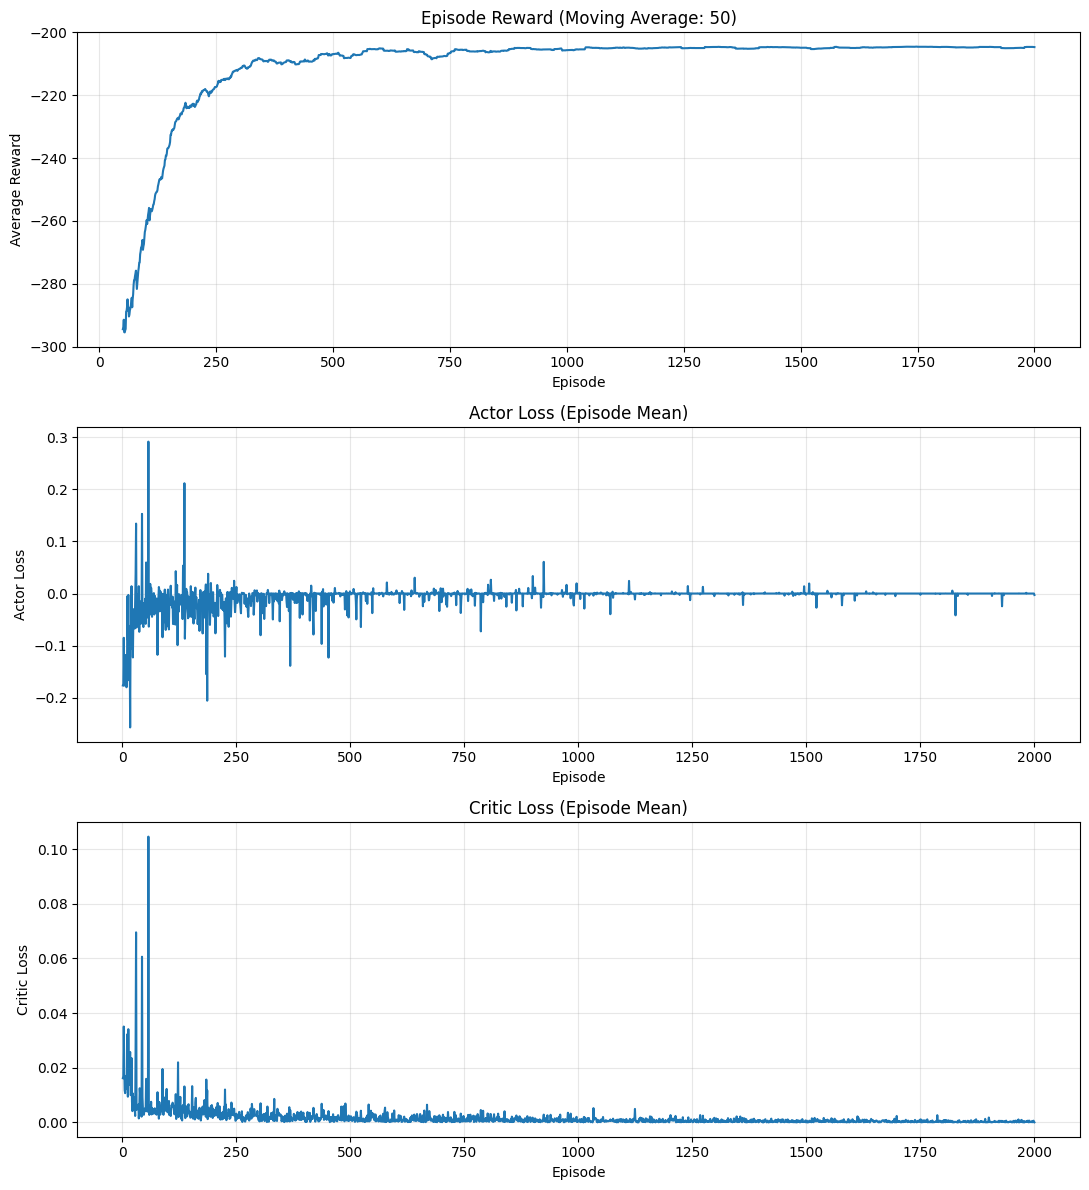

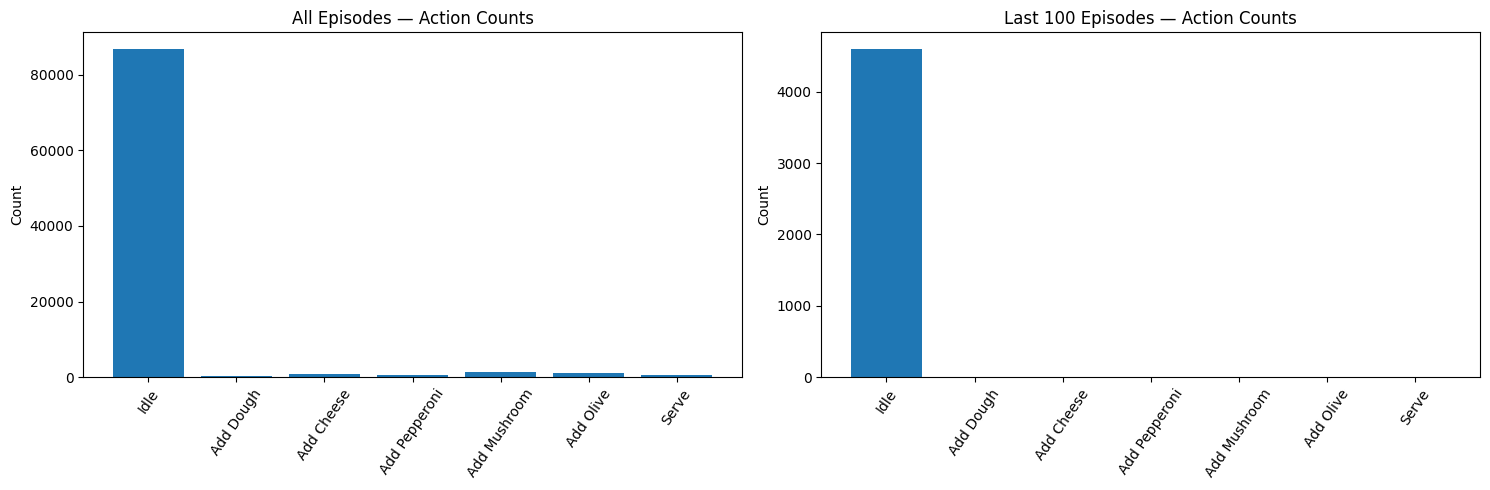

=== Last 100 Episodes Action Distribution ===
Idle            :  99.85%
Add Dough       :   0.02%
Add Cheese      :   0.02%
Add Pepperoni   :   0.02%
Add Mushroom    :   0.02%
Add Olive       :   0.04%
Serve           :   0.02%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 2000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        actor_loss = -torch.log(pi_a) * delta.detach()
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss.mean() + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
# 학습 완료 후 이 셀을 다시 실행하면 학습된 모델이 새 모델로 초기화됩니다.
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 1-1 (Seed 42) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

**현상:** 2,000에피소드 학습 결과, 마지막 100에피소드 평균 보상은 −204.86, 주문 처리 성공률은 0.00%로 나타남. 전체 8,000건의 주문 중 8건만 성공하였으며, 마지막 100에피소드의 Idle 행동 비율은 99.85%를 기록함. 평균 보상은 학습 초기 약 −295에서 −205 수준까지 개선되었으나, 이후 정체되는 모습을 보임.

**원인 분석**: 학습 초기에 평균 보상이 개선되었으나, 주문 처리 성공률의 향상으로 이어지지는 못함. 학습 후반에는 Idle 행동 비율이 99.85%에 도달하면서 재료 추가 및 서빙 행동이 거의 선택되지 않았고, 대부분의 주문이 시간 초과됨. 평균 보상의 개선은 주문 처리 능력의 향상보다는 불필요한 행동에 따른 패널티 감소와 관련되었을 가능성이 있으나, 정확한 원인을 확인하려면 학습 구간별 행동 분포를 추가로 분석할 필요가 있음.

**결론 및 시사점:** 동일한 환경과 시드를 사용한 REINFORCE with Baseline 실험 7-1의 주문 성공률 43.50%와 비교하여 낮은 성능을 보임. 특히 학습 방식과 하이퍼파라미터를 변경했음에도 Idle 행동 편중이 지속되어, 현재 설정에서는 충분한 탐색이 이루어지지 않은 것으로 추정됨. 따라서 이후 실험에서는 환경 조건을 유지하고 Actor Loss에 엔트로피 보너스를 추가하여 다양한 행동의 탐색을 유도하고, 정책 고착 현상과 주문 처리 성공률의 변화를 확인하고자 함

####
## 실험 2-1: Actor-Critic (Seed 42, 엔트로피 보너스 추가)

### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- 학습 2,000에피소드
- 랜덤 시드 42
- **(추가) 엔트로피 보너스 계수 0.01**

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp2_1_seed42_checkpoints/actor_critic_exp2_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -297.47 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -279.62 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -260.36 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -251.91 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -243.39 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -237.90 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -239.57 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -242.45 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -244.52 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -237.22 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_exp2_1_seed42_checkpoints/actor_critic_exp2_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -236.23 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -231

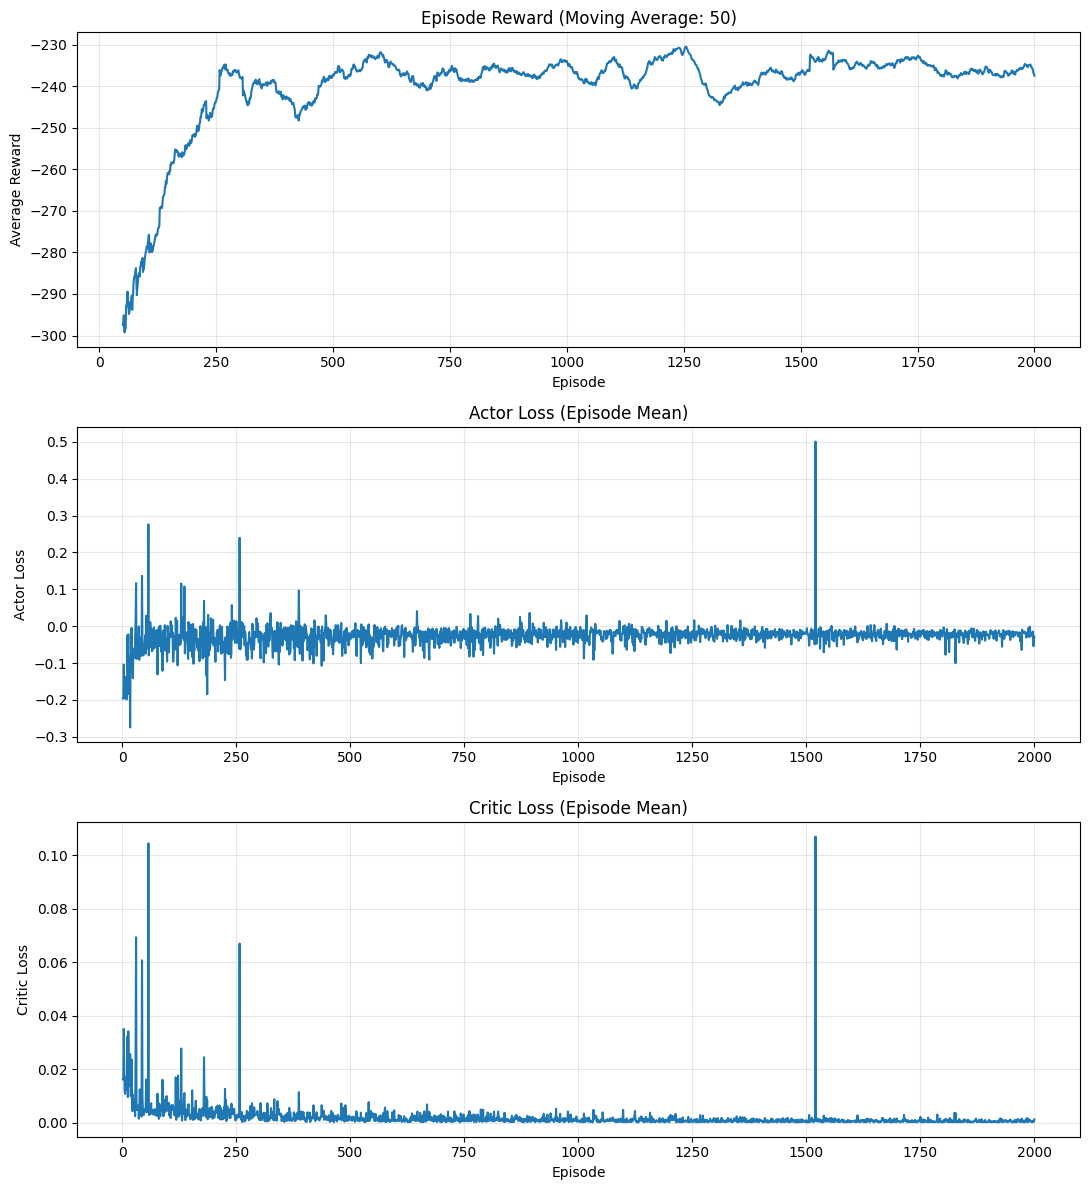

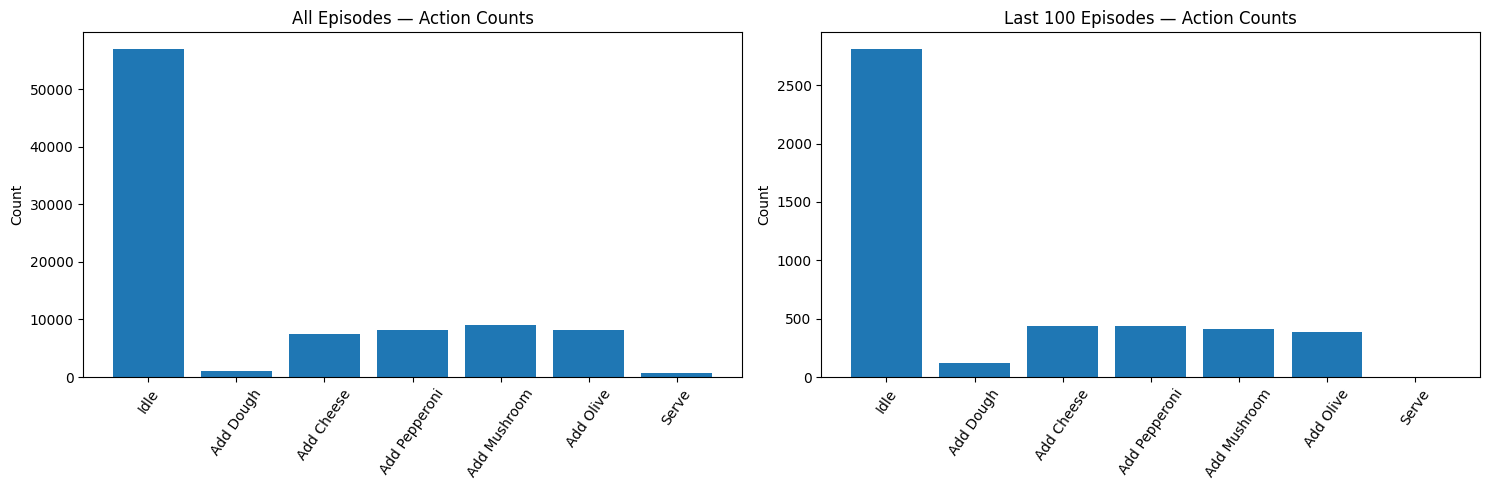

=== Last 100 Episodes Action Distribution ===
Idle            :  61.00%
Add Dough       :   2.60%
Add Cheese      :   9.54%
Add Pepperoni   :   9.50%
Add Mushroom    :   8.98%
Add Olive       :   8.31%
Serve           :   0.07%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 2000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)

        entropy = Categorical(probs=pi).entropy().mean() # ⭐ 엔트로피 보너스 추가
        actor_loss = (
            (-torch.log(pi_a) * delta.detach()).mean()
            - 0.01 * entropy
        )

        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
# 학습 완료 후 이 셀을 다시 실행하면 학습된 모델이 새 모델로 초기화됩니다.
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp2_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp2_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print("=== Actor-Critic Experiment 2-1 (Seed 42, Entropy Bonus 0.01) ===")
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

### 추가 분석: 주문 처리 실패 원인

- 학습된 모델의 행동을 시드 42에서 관찰
- 주문 메뉴, 남은 시간, 선택 행동, 조리대 상태 및 보상 확인
- 유효하지 않은 재료 추가, 서빙 시도 및 시간 초과 원인 분석

In [ ]:
from pathlib import Path

# 실험 2-1에서 저장한 최종 모델
CHECKPOINT_PATH = Path('actor_critic_exp2_1_seed42_checkpoints/actor_critic_exp2_1_seed42_ep2000.pth')

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f'체크포인트를 찾지 못했습니다: {CHECKPOINT_PATH}\n'
        '실험 2-1에서 저장한 ep2000.pth를 Colab에 업로드하거나 경로를 수정하세요.'
    )

model = ActorCritic().to(device)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True))
model.eval()
print('Loaded:', CHECKPOINT_PATH)

ACTION_NAMES = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
                'Add Mushroom', 'Add Olive', 'Serve']
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
INGREDIENT_NAMES = ['Dough', 'Cheese', 'Pepperoni', 'Mushroom', 'Olive']

DEMO_EPISODES = 1
PRINT_STEPS = True

def order_text(orders):
    if not orders:
        return 'None'
    return ' | '.join(f"{MENU_NAMES[o['menu']]}({o['timer']} steps)" for o in orders)

def counter_text(counter):
    ingredients = [name for name, flag in zip(INGREDIENT_NAMES, counter) if flag == 1]
    return ', '.join(ingredients) if ingredients else 'Empty'

# 디버깅을 위한 진단 집계
stats = {'steps': 0, 'idle': 0, 'invalid_add': 0, 'valid_add': 0,
         'serve_attempts': 0, 'wrong_serve': 0, 'correct_serve': 0,
         'ready_not_served': 0, 'timeouts': 0, 'total_reward': 0.0}

demo_env = PizzaShopEnv()
for ep in range(1, DEMO_EPISODES + 1):
    state, _ = demo_env.reset(seed=SEED + ep - 1)
    done = False
    ep_reward = 0.0
    ep_success = 0
    ep_timeout = 0
    print(f'\n========== Diagnostic Episode {ep} (seed={SEED + ep - 1}) ==========')
    print('Initial orders:', order_text(demo_env.orders))

    while not done:
        before_counter = demo_env.counter.copy()
        before_orders = [o.copy() for o in demo_env.orders]
        before_ready = bool(before_orders) and np.array_equal(
            before_counter, demo_env.menus[before_orders[0]['menu']]
        )

        with torch.no_grad():
            probs = model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = demo_env.step(action)
        done = terminated or truncated
        stats['steps'] += 1
        stats['total_reward'] += reward
        ep_reward += reward
        ep_success += info['success_count']
        ep_timeout += info['timeout_count']
        stats['timeouts'] += info['timeout_count']

        if action == 0:
            stats['idle'] += 1
        if action in (1, 2, 3, 4, 5):
            # 재료 추가 성공 시 조리대의 해당 재료 플래그가 0 -> 1로 변경됨
            ingredient_idx = action - 1
            valid = before_counter[ingredient_idx] == 0 and demo_env.counter[ingredient_idx] == 1
            stats['valid_add' if valid else 'invalid_add'] += 1
        if action == 6:
            stats['serve_attempts'] += 1
            if info['success_count']:
                stats['correct_serve'] += 1
            else:
                stats['wrong_serve'] += 1
        if before_ready and action != 6:
            stats['ready_not_served'] += 1

        if PRINT_STEPS:
            notes = []
            if action in (1, 2, 3, 4, 5) and not valid:
                notes.append('INVALID INGREDIENT')
            if action == 6:
                notes.append('CORRECT SERVE' if info['success_count'] else 'WRONG SERVE')
            if before_ready and action != 6:
                notes.append('READY BUT NOT SERVED')
            if info['timeout_count']:
                notes.append(f"TIMEOUT x{info['timeout_count']}")
            print(f"Step {demo_env.steps:02d} | Orders: {order_text(before_orders)}")
            print(f"  Action: {ACTION_NAMES[action]:<14} | Counter: {counter_text(before_counter)} -> {counter_text(demo_env.counter)}")
            print(f"  Reward: {reward:+7.1f} | After orders: {order_text(demo_env.orders)}"
                  + (f" | {'; '.join(notes)}" if notes else ''))

        state = next_state

    print(f'Episode result: reward={ep_reward:.2f}, success={ep_success}, timeout={ep_timeout}')

print('\n========== Diagnostic Summary ==========')
print('Total steps:', stats['steps'])
print('Idle:', stats['idle'])
print('Valid ingredient adds:', stats['valid_add'])
print('Invalid ingredient adds:', stats['invalid_add'])
print('Serve attempts:', stats['serve_attempts'])
print('Correct / wrong serves:', stats['correct_serve'], '/', stats['wrong_serve'])
print('Ready but not served (steps):', stats['ready_not_served'])
print('Timeout orders:', stats['timeouts'])
print('Total reward:', round(stats['total_reward'], 2))

Loaded: actor_critic_exp2_1_seed42_checkpoints/actor_critic_exp2_1_seed42_ep2000.pth

========== Diagnostic Episode 1 (seed=42) ==========
Initial orders: Cheese(46 steps) | Mushroom(41 steps) | Pepperoni(47 steps) | Cheese(45 steps)
Step 01 | Orders: Cheese(46 steps) | Mushroom(41 steps) | Pepperoni(47 steps) | Cheese(45 steps)
  Action: Add Cheese     | Counter: Empty -> Empty
  Reward:    -2.1 | After orders: Cheese(45 steps) | Mushroom(40 steps) | Pepperoni(46 steps) | Cheese(44 steps) | INVALID INGREDIENT
Step 02 | Orders: Cheese(45 steps) | Mushroom(40 steps) | Pepperoni(46 steps) | Cheese(44 steps)
  Action: Add Pepperoni  | Counter: Empty -> Empty
  Reward:    -2.1 | After orders: Cheese(44 steps) | Mushroom(39 steps) | Pepperoni(45 steps) | Cheese(43 steps) | INVALID INGREDIENT
Step 03 | Orders: Cheese(44 steps) | Mushroom(39 steps) | Pepperoni(45 steps) | Cheese(43 steps)
  Action: Add Mushroom   | Counter: Empty -> Empty
  Reward:    -2.1 | After orders: Cheese(43 steps) | M

**현상:** 엔트로피 보너스 계수 0.01을 적용한 결과, 마지막 100에피소드의 Idle 행동 비율이 99.85%에서 61.00%로 감소함. 그러나 도우 추가 비율은 2.60%, 서빙 비율은 0.07%에 그쳤으며, 주문 처리 성공률은 0.00%로 유지됨. 평균 보상도 −204.86에서 −237.12로 감소함.

**원인 분석:** 추가 행동 분석 결과, 시드 42의 한 에피소드에서 도우 추가 없이 치즈와 토핑을 선택하여 재료 추가 27회가 모두 무효 처리됨. 조리대가 끝까지 비어 있었고 서빙도 시도하지 않아 주문 4개가 모두 시간 초과됨. 이를 통해 단순한 시간 부족보다 필수 재료 추가 순서를 학습하지 못한 것이 주요 실패 원인으로 확인됨.

**결론 및 시사점:** 엔트로피 보너스는 Idle 행동 편중을 완화하였으나, 올바른 조리 순서와 서빙 행동의 학습으로 이어지지 못함. 따라서 다음 실험에서는 **Reward Shaping 기법**을 적용하여 올바른 재료 추가 행동에 중간 보상을 제공하고, 무효 행동을 줄이면서 도우부터 순서대로 조리하도록 학습을 개선하고자 함.

## 실험 3-1: Actor-Critic (Seed 42, Reward Shaping 추가)

### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- 학습 2,000에피소드
- 랜덤 시드 42
- 엔트로피 보너스 계수 0.01 유지
- **(추가) Reward Shaping: 현재 주문에 필요한 재료를 올바른 순서로 추가할 경우 중간 보상 +5**

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp3_1_seed42_checkpoints/actor_critic_exp3_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -278.70 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -262.37 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -259.26 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -245.37 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -246.68 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -244.02 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -232.91 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -229.26 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -229.44 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -213.68 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_exp3_1_seed42_checkpoints/actor_critic_exp3_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -199.97 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -191

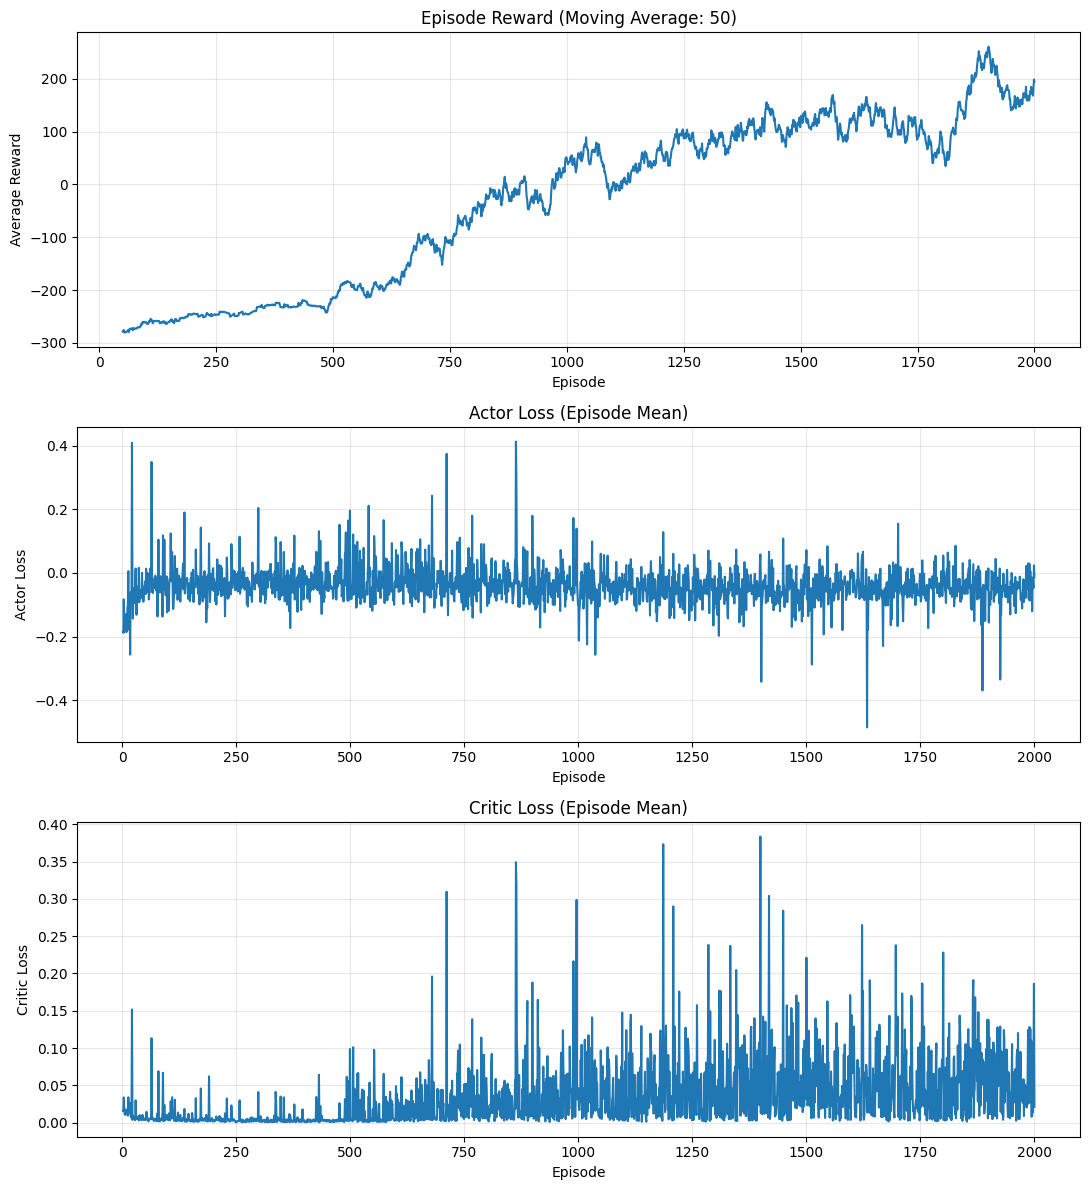

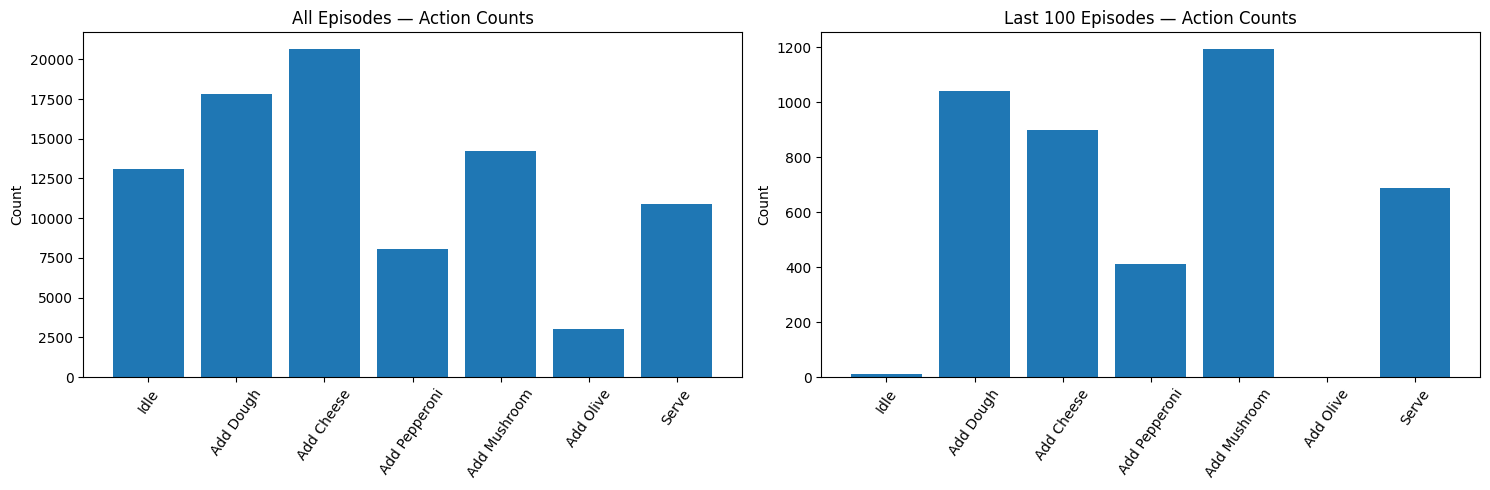

=== Last 100 Episodes Action Distribution ===
Idle            :   0.28%
Add Dough       :  24.49%
Add Cheese      :  21.17%
Add Pepperoni   :   9.68%
Add Mushroom    :  28.14%
Add Olive       :   0.02%
Serve           :  16.20%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 2000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += SHAPING_REWARD
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += SHAPING_REWARD
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += SHAPING_REWARD
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp3_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp3_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 3-1 (Seed 42, Entropy 0.01, Reward Shaping +5) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        58        35         62.37%
Pepperoni          99        47        52         47.47%
Mushroom          102        71        31         69.61%
Special           106         0       106          0.00%
Total: 176/400 (44.00%)


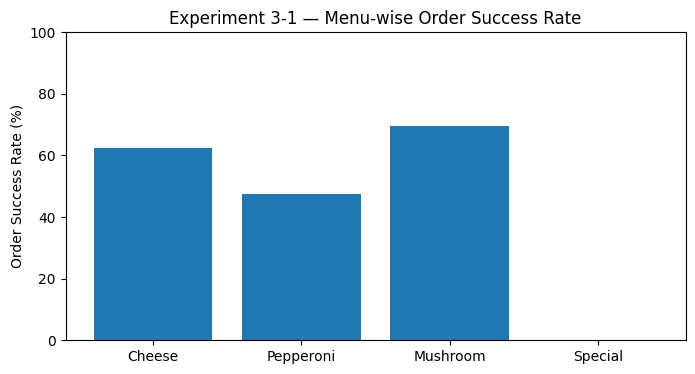

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp3_1_seed42_ep2000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 3-1 — Menu-wise Order Success Rate')
plt.show()

**현상:** Reward Shaping 적용 후 마지막 100에피소드의 주문 처리 성공률이 실험 2-1의 0.00%에서 47.75%로 상승함. Idle 행동 비율은 0.28%로 감소하고 도우 추가 및 서빙 행동이 증가함. 추가 평가에서는 치즈 62.37%, 페퍼로니 47.47%, 버섯 69.61%의 성공률을 기록했으나, 스페셜 피자는 0.00%에 그침.

**원인 분석:** 올바른 재료 추가에 중간 보상 +5를 제공하면서 기본 조리 행동이 활성화되고 주문 성공으로 이어진 것으로 판단됨. 그러나 올리브 추가 비율이 0.02%로 매우 낮아, 올리브가 필수인 스페셜 피자의 조합을 완성하지 못했을 가능성이 있음.

**결론 및 시사점:** Reward Shaping은 Idle 편중을 완화하고 주문 처리 성공률을 개선하는 데 효과적이었으나, 메뉴별 성능 차이가 크게 나타남. 이후 실험에서는 스페셜 피자에 필요한 재료 선택을 개선하여 메뉴별 성공률의 편차를 줄일 필요가 있음.

####
## 실험 4-1: Actor-Critic (Seed 42, 단계별 Reward Shaping 적용)
### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- 학습 2,000에피소드
- 랜덤 시드 42
- 엔트로피 보너스 계수 0.01 유지
- **(변경) 단계별 Reward Shaping: 올바른 재료 추가 시 +5, 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10**

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp4_1_seed42_checkpoints/actor_critic_exp4_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -274.78 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -260.26 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -250.96 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -234.12 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -239.60 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -240.16 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -223.02 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -227.89 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -237.66 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -207.82 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_exp4_1_seed42_checkpoints/actor_critic_exp4_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -199.10 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -183

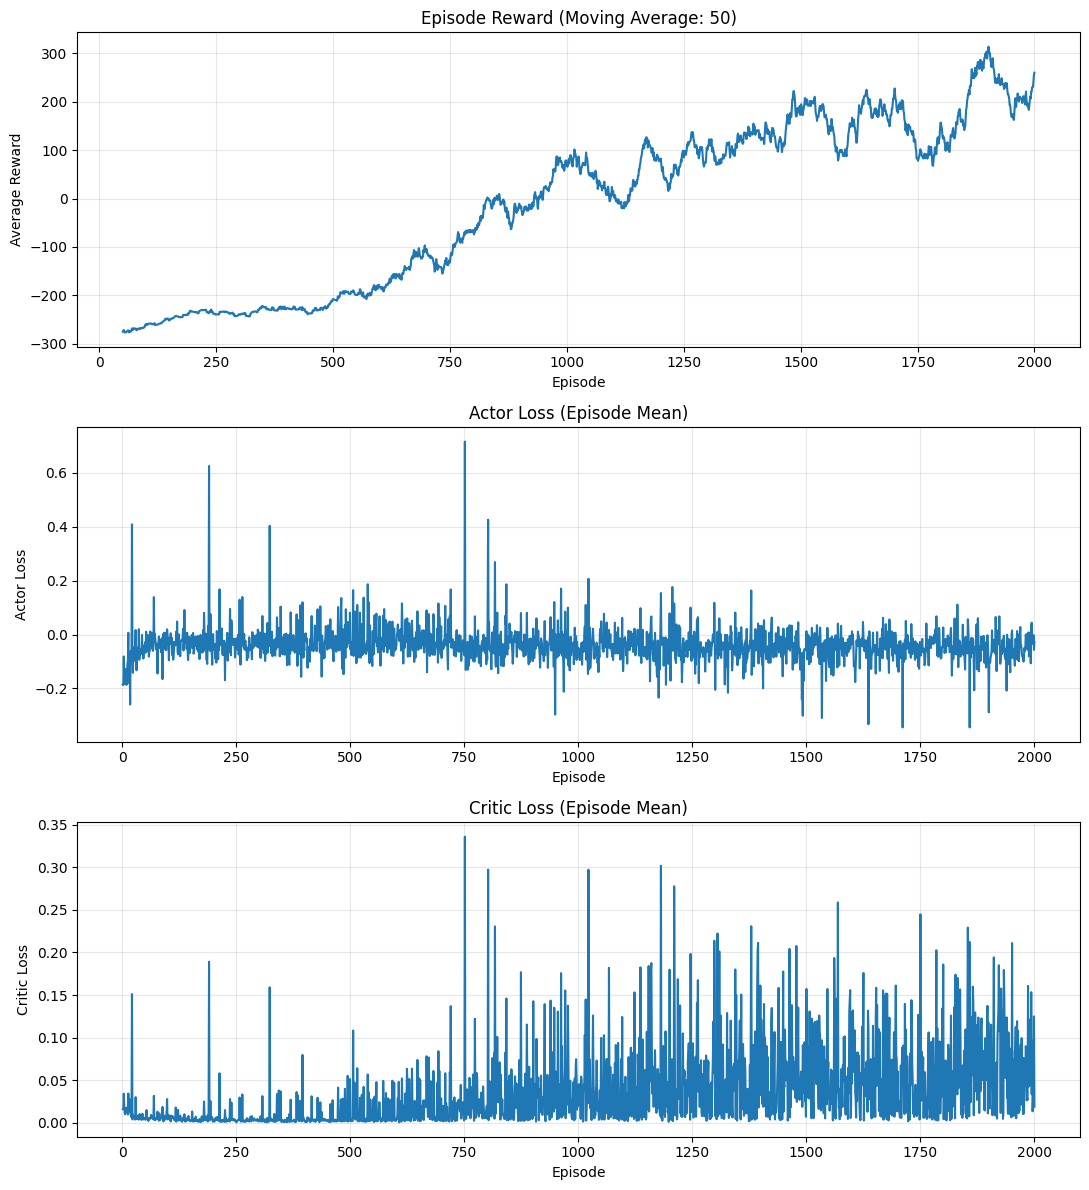

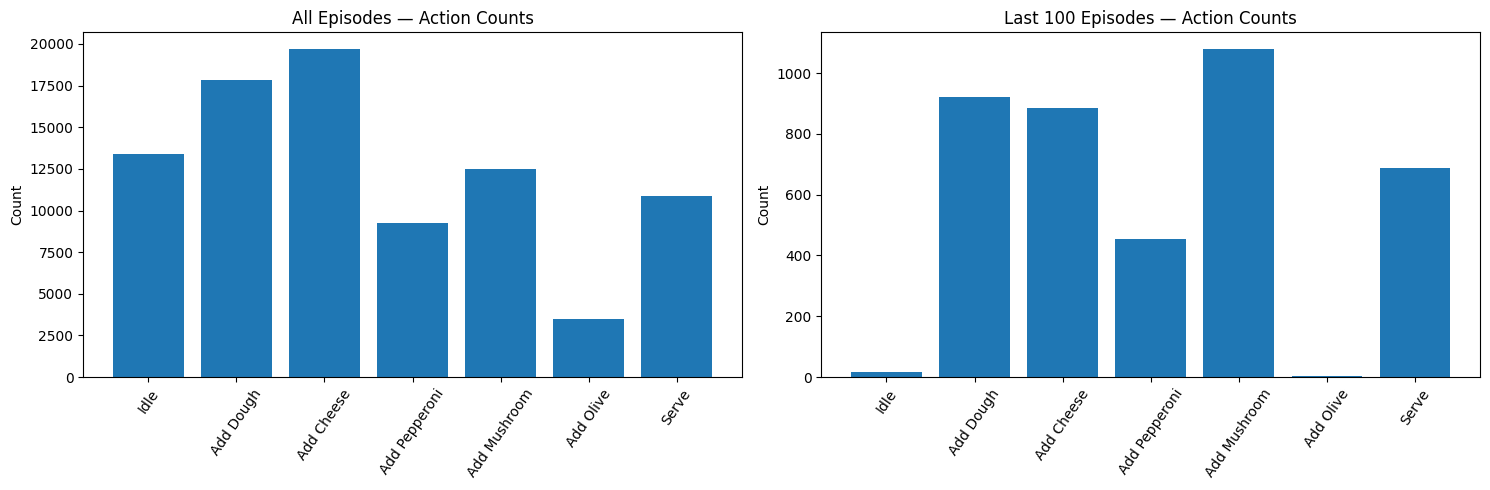

=== Last 100 Episodes Action Distribution ===
Idle            :   0.37%
Add Dough       :  22.80%
Add Cheese      :  21.86%
Add Pepperoni   :  11.20%
Add Mushroom    :  26.71%
Add Olive       :   0.05%
Serve           :  16.99%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 2000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp4_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp4_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 4-1 (Seed 42, Entropy 0.01, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        62        31         66.67%
Pepperoni          99        57        42         57.58%
Mushroom          102        53        49         51.96%
Special           106         0       106          0.00%
Total: 172/400 (43.00%)


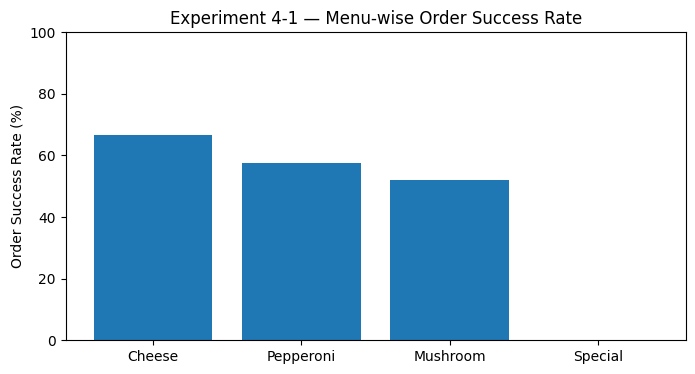

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp4_1_seed42_ep2000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 4-1 — Menu-wise Order Success Rate')
plt.show()

**현상:** 마지막 재료 추가 보상을 +10으로 높인 결과, 마지막 100에피소드의 주문 처리 성공률이 실험 3-1의 47.75%에서 51.25%로 상승함. 그러나 별도 평가에서는 전체 성공률이 43.00%로 나타났으며, 스페셜 피자는 106건 모두 실패함. 올리브를 추가하는 행동의 선택 비율도 0.05%에 그침.

**원인 분석:** 피자 완성에 대한 추가 보상으로 학습 후반의 성공률은 소폭 상승했으나, 올리브를 추가하는 행동의 선택 비율은 거의 증가하지 않음. 이는 보상을 높이더라도 스페셜 피자에 필요한 재료 조합과 조리 순서를 충분히 학습하지 못했을 가능성을 보여줌.

**결론 및 시사점:** 단계별 Reward Shaping은 학습 후반의 주문 처리 성공률을 소폭 개선했으나, 별도 평가에서는 성능 향상이 확인되지 않았으며 스페셜 피자 문제도 해결하지 못함. 특히 올리브를 추가하는 행동이 거의 선택되지 않아, 다음 실험에서는 엔트로피 보너스 계수를 높여 올리브 추가 행동의 탐색이 증가하고 스페셜 피자의 주문 처리 성공률이 개선되는지 확인하고자 함.

####
## 실험 5-1: Actor-Critic (Seed 42, 단계별 Reward Shaping + 엔트로피 보너스 계수 증가)

### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- 학습 2,000에피소드
- 랜덤 시드 42
- 단계별 Reward Shaping 유지: 올바른 재료 추가 시 +5, 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10
- **(변경) 엔트로피 보너스 계수 0.01 → 0.05로 증가**

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp5_1_seed42_checkpoints/actor_critic_exp5_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -261.18 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -267.54 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -245.78 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -228.34 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -223.25 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -187.32 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -188.67 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -155.12 | Success: 1 | Timeout: 3
Episode  450 | Avg Reward (50):  -140.83 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -158.86 | Success: 1 | Timeout: 3
Checkpoint saved: episode 500 -> actor_critic_exp5_1_seed42_checkpoints/actor_critic_exp5_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -109.60 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):   -63

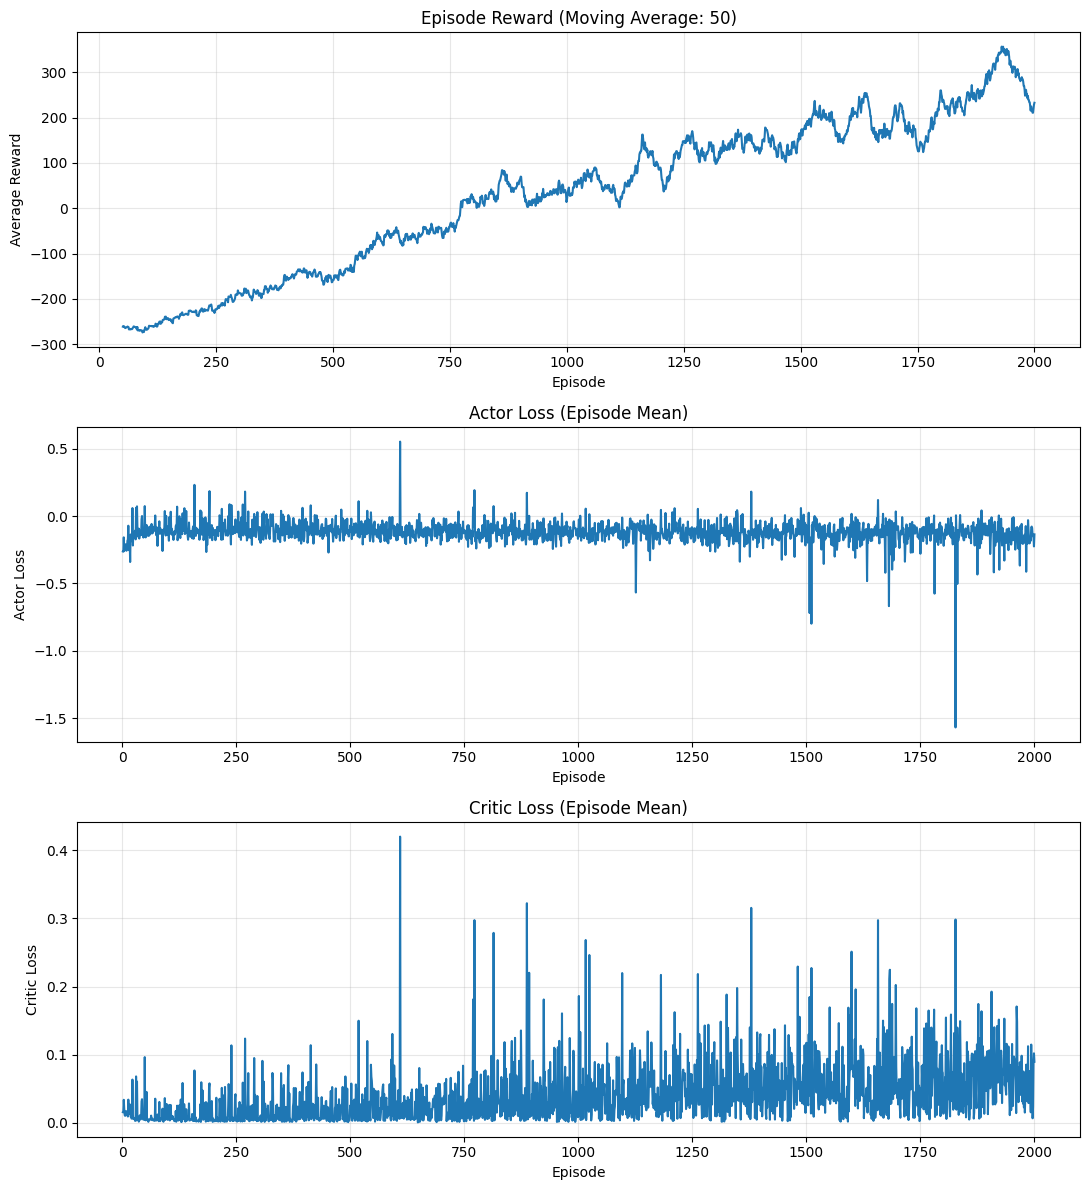

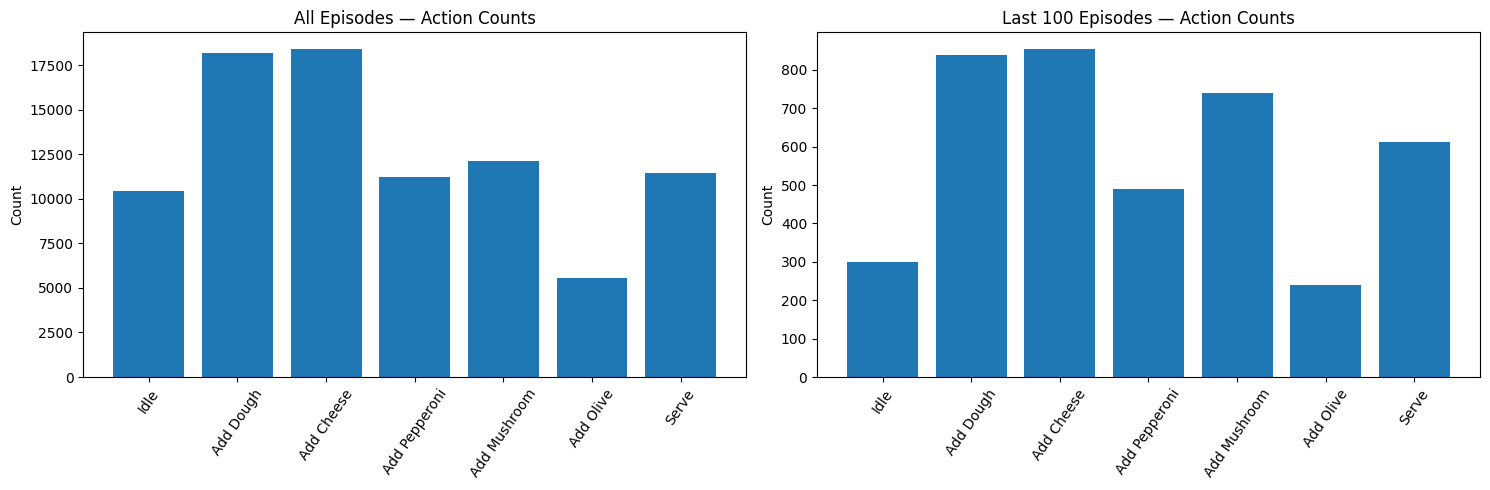

=== Last 100 Episodes Action Distribution ===
Idle            :   7.36%
Add Dough       :  20.56%
Add Cheese      :  20.98%
Add Pepperoni   :  12.02%
Add Mushroom    :  18.16%
Add Olive       :   5.89%
Serve           :  15.04%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 2000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp5_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp5_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 5-1 (Seed 42, Entropy 0.05, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        62        31         66.67%
Pepperoni          99        57        42         57.58%
Mushroom          102        62        40         60.78%
Special           106        30        76         28.30%
Total: 211/400 (52.75%)


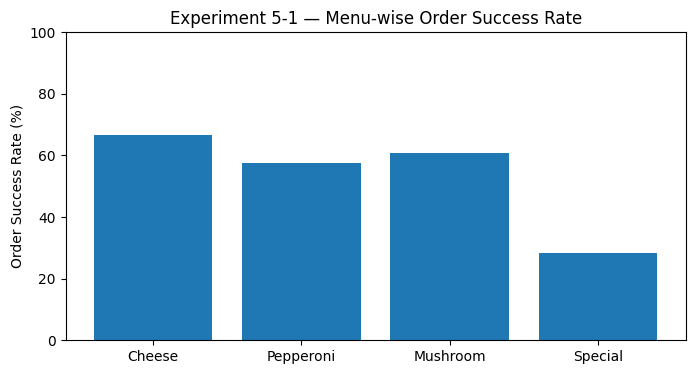

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp5_1_seed42_ep2000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 5-1 — Menu-wise Order Success Rate')
plt.show()

**현상:** 엔트로피 보너스 계수를 0.01에서 0.05로 높인 결과, 마지막 100에피소드의 주문 처리 성공률이 실험 4-1의 51.25%에서 57.25%로 상승함. 올리브를 추가하는 행동의 선택 비율도 0.05%에서 5.89%로 증가했으며, 별도 평가에서 전체 성공률은 43.00%에서 52.75%로, 스페셜 피자 성공률은 0.00%에서 28.30%로 개선됨.

**원인 분석:** 엔트로피 보너스 계수를 높이면서 다양한 행동에 대한 탐색이 촉진되어, 이전 실험에서 거의 선택되지 않았던 올리브 추가 행동의 선택 비율이 증가한 것으로 판단됨. 이에 따라 스페셜 피자에 필요한 재료 조합을 완성할 기회가 늘어나 주문 처리 성공률 개선에 기여했을 가능성이 있음.

**결론 및 시사점:** 엔트로피 보너스 계수를 높인 결과, 학습 후반의 주문 처리 성능이 개선되고 이전 실험에서 성공하지 못했던 스페셜 피자도 일부 처리할 수 있게 됨. 그러나 스페셜 피자 성공률은 28.30%로 다른 메뉴보다 여전히 낮아 추가적인 개선이 필요함. 따라서 다음 실험에서는 현재의 탐색 수준을 유지하면서 학습 횟수를 늘려, 스페셜 피자를 포함한 전체 주문 처리 성공률이 추가로 개선되는지 확인하고자 함.

## 실험 6-1: Actor-Critic (Seed 42, 학습 에피소드 증가)

### 실험 조건
- 메뉴 4종, 재료 5종, 행동 7개
- 최대 대기 주문 4개
- 주문 타이머 36~48스텝
- 정답 서빙 보상 +150, 시간 초과 −50
- 잘못된 서빙 −15, 잘못된 재료 추가 −2, 스텝당 −0.1
- 신경망 구조: 공유 은닉층 256개, Actor/Critic 출력층 분리
- 학습 방식: 1-step TD, 10스텝 단위 업데이트
- 학습률 0.0002, 할인율 γ=0.98
- 학습 시 보상 스케일링 적용 (÷100)
- **(변경) 학습 2,000에피소드 → 4,000에피소드로 증가**
- 랜덤 시드 42
- 단계별 Reward Shaping 유지: 올바른 재료 추가 시 +5, 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10
- 엔트로피 보너스 계수 0.05 유지

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -261.18 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -267.54 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -245.78 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -228.34 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -223.25 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -187.32 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -188.67 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -155.12 | Success: 1 | Timeout: 3
Episode  450 | Avg Reward (50):  -140.83 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -158.86 | Success: 1 | Timeout: 3
Checkpoint saved: episode 500 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -109.60 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):   -63

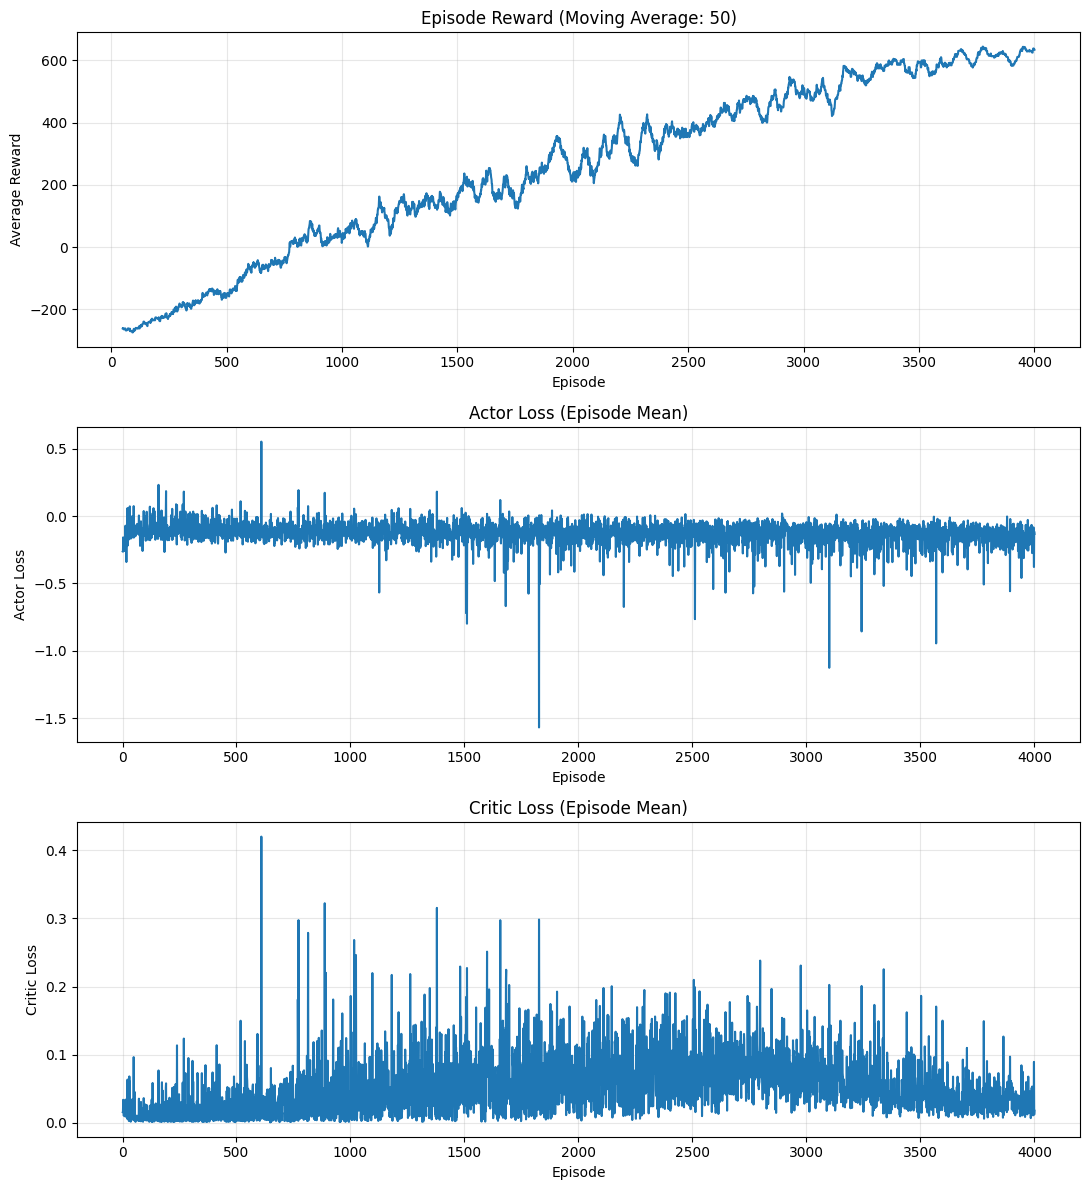

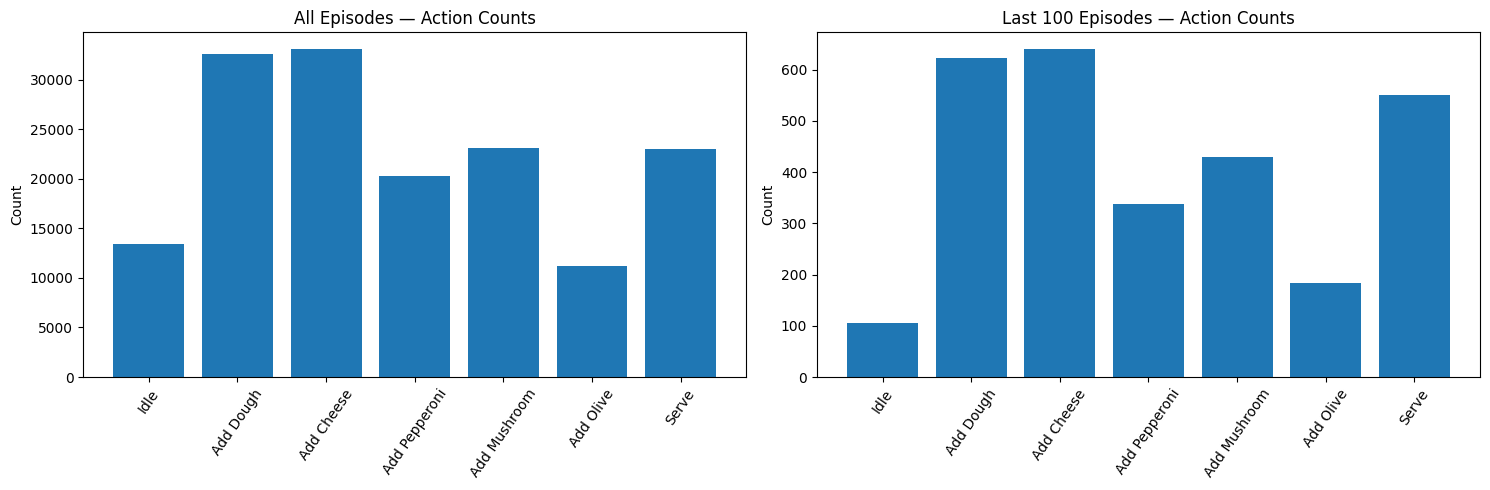

=== Last 100 Episodes Action Distribution ===
Idle            :   3.69%
Add Dough       :  21.69%
Add Cheese      :  22.32%
Add Pepperoni   :  11.73%
Add Mushroom    :  14.97%
Add Olive       :   6.41%
Serve           :  19.19%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 4000 # ⭐ 학습 에피소드 2000 → 4000으로 증가
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp6_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp6_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 6-1 (Seed 42, Entropy 0.05, 4000 Episodes, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        90         3         96.77%
Pepperoni          99        93         6         93.94%
Mushroom          102        91        11         89.22%
Special           106       102         4         96.23%
Total: 376/400 (94.00%)


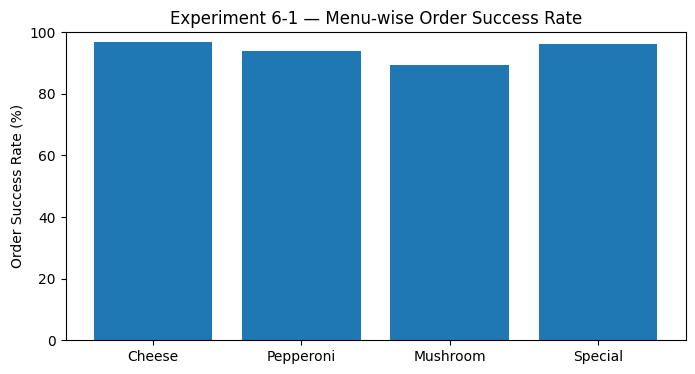

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp6_1_seed42_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 6-1 — Menu-wise Order Success Rate')
plt.show()

In [ ]:
# 9. ZIP Checkpoints & Download
zip_path = shutil.make_archive(str(CHECKPOINT_DIR), 'zip', str(CHECKPOINT_DIR))
print('Created:', zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Colab이 아닌 환경입니다. 위 경로에서 ZIP 파일을 직접 가져가세요.')

Created: /content/actor_critic_exp6_1_seed42_checkpoints.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**현상:** 학습 횟수를 2,000에피소드에서 4,000에피소드로 늘린 결과, 마지막 100에피소드의 주문 처리 성공률이 실험 5-1의 57.25%에서 97.00%로 상승함. 별도 평가에서도 전체 성공률이 52.75%에서 94.00%로 증가했으며, 특히 스페셜 피자 성공률은 28.30%에서 96.23%로 크게 개선됨. 올리브 추가 행동의 선택 비율은 5.89%에서 6.41%로 증가하고, Idle 행동의 선택 비율은 7.36%에서 3.69%로 감소함.

**원인 분석:** 엔트로피 보너스 계수 0.05를 유지하면서 학습 횟수를 늘린 결과, 다양한 주문 처리 상황을 반복적으로 경험하며 각 메뉴에 필요한 재료 추가와 서빙 방법을 더 잘 학습했을 가능성이 있음. 학습 후반까지 평균 보상이 상승하여 마지막 100에피소드에서 638.67을 기록했으며, 별도 평가에서도 모든 메뉴가 약 89% 이상의 성공률을 보인 점이 이를 뒷받침함.

**결론 및 시사점:** 학습 횟수를 4,000에피소드로 늘린 결과, 전체 주문 처리 성능이 크게 개선되었으며 스페셜 피자도 96.23%의 높은 성공률을 달성함. 이는 실험 5-1에서 나타난 성능 상승 추세가 추가 학습에서도 이어졌음을 보여주며, 현재 설정에서는 충분한 학습 횟수를 확보하는 것이 복잡한 주문 처리 환경의 성능 향상에 효과적일 가능성을 시사함.

####
## 추가 실험(test): Actor-Critic (Seed 42, Entropy 0.01 유지, 학습 4,000에피소드)
실험 목적
실험 4-1의 엔트로피 보너스 계수 0.01과 Reward Shaping 설정을 유지한 상태에서 학습 횟수만 2,000에피소드에서 4,000에피소드로 증가시켜, 학습 횟수 증가만으로 주문 처리 성능이 개선되는지 확인함.

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_test_seed42_checkpoints/actor_critic_test_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -274.78 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -260.26 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -250.96 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -234.12 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -239.60 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -240.16 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -223.02 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -227.89 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -237.66 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -207.82 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_test_seed42_checkpoints/actor_critic_test_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -199.10 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -183.93 | Su

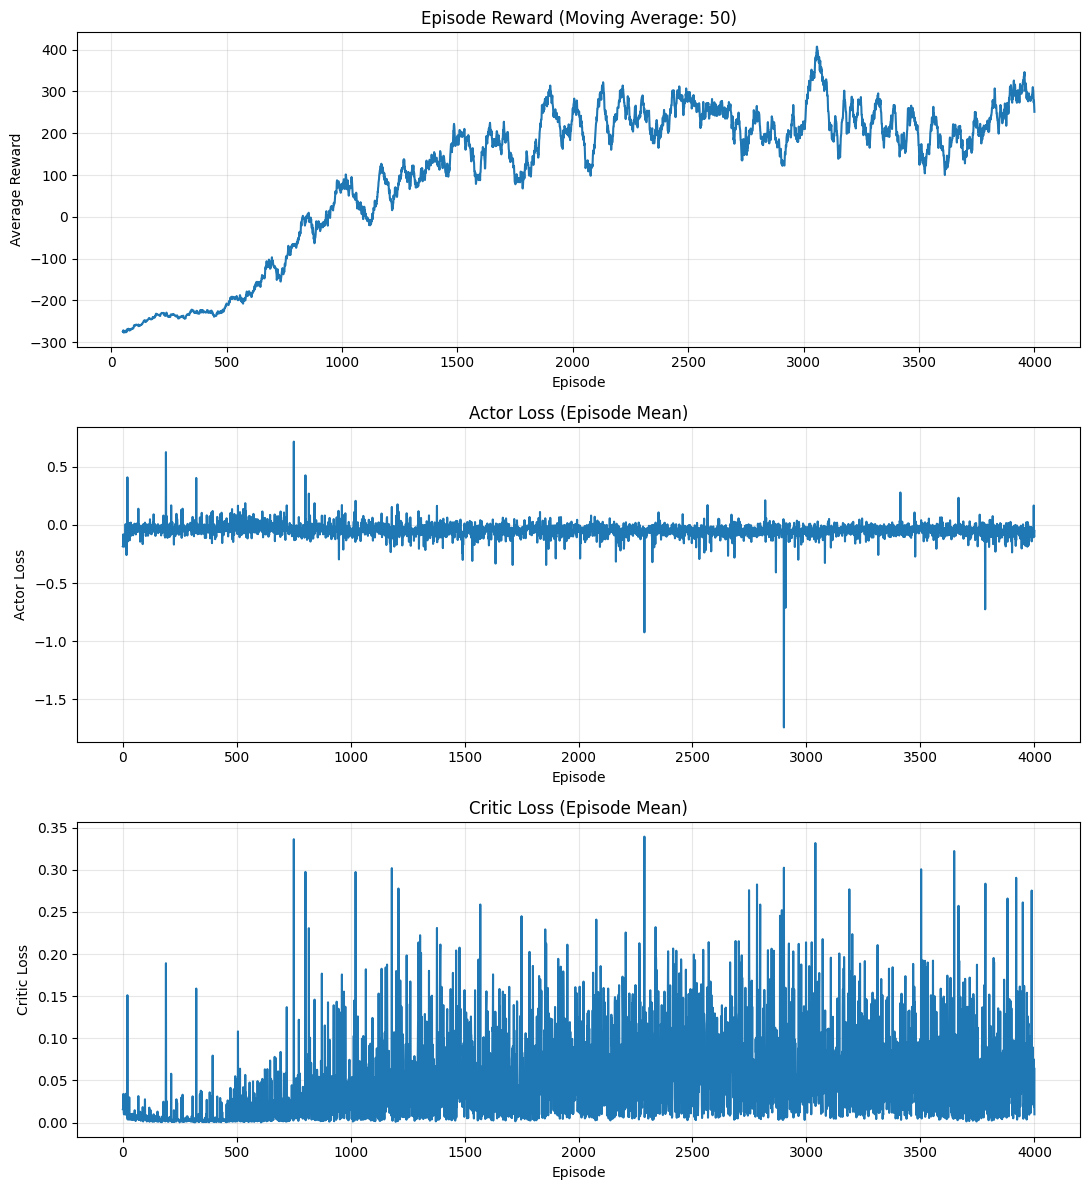

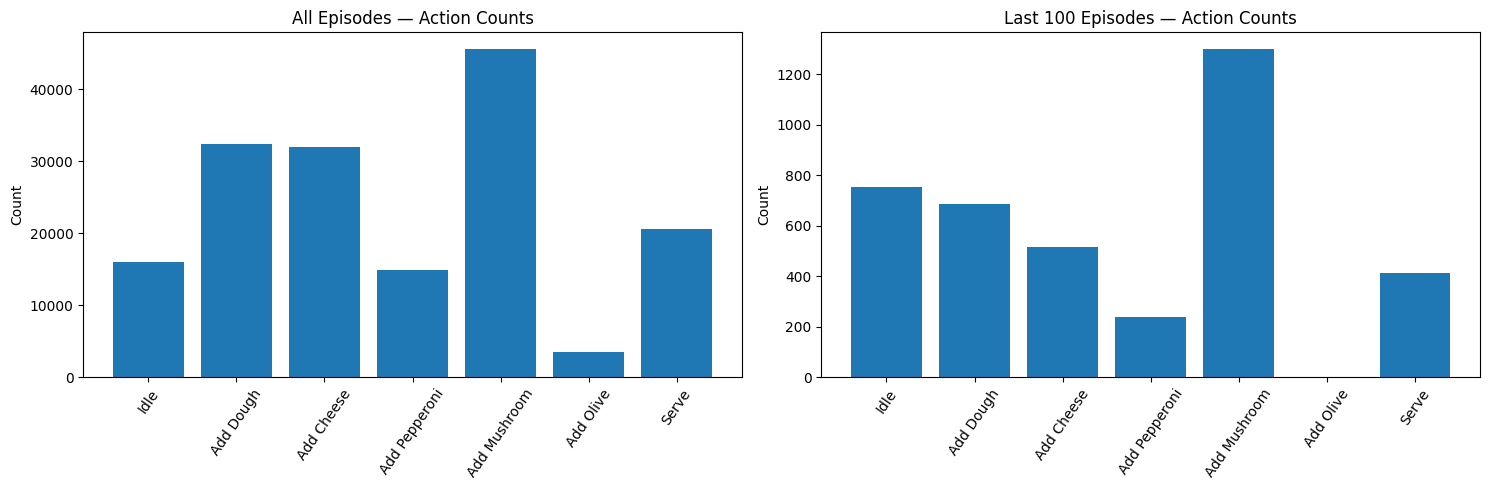

=== Last 100 Episodes Action Distribution ===
Idle            :  19.31%
Add Dough       :  17.52%
Add Cheese      :  13.16%
Add Pepperoni   :   6.09%
Add Mushroom    :  33.32%
Add Olive       :   0.03%
Serve           :  10.58%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 4000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_test_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_test_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment test (Seed 42, Entropy 0.01, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        58        35         62.37%
Pepperoni          99        60        39         60.61%
Mushroom          102        76        26         74.51%
Special           106         0       106          0.00%
Total: 194/400 (48.50%)


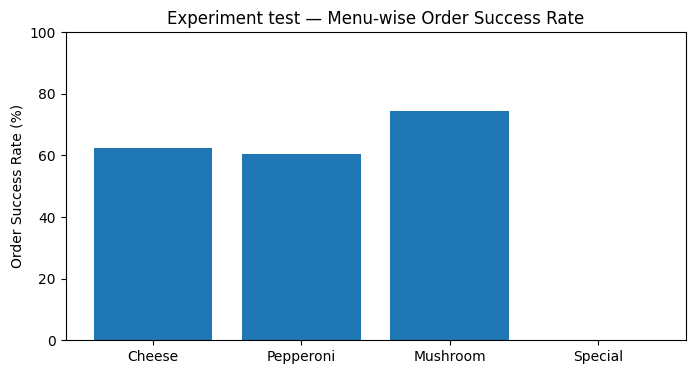

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_test_seed42_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment test — Menu-wise Order Success Rate')
plt.show()

**현상:** 실험 4-1의 엔트로피 보너스 계수 0.01과 Reward Shaping 설정을 유지하면서 학습 횟수를 4,000에피소드로 늘린 결과, 마지막 100에피소드의 주문 처리 성공률은 59.25%, 평균 보상은 287.05로 나타남. 별도 평가에서는 전체 주문 처리 성공률 48.50%를 기록했으며, 치즈 62.37%, 페퍼로니 60.61%, 버섯 74.51%의 성공률을 보인 반면 스페셜 피자는 0.00%로 나타남. 마지막 100에피소드에서 올리브 추가 행동의 선택 비율도 0.03%에 그침.

**원인 분석:** 엔트로피 보너스 계수 0.01을 유지한 상태에서는 학습 횟수를 늘렸음에도 올리브 추가 행동이 거의 선택되지 않았으며, 스페셜 피자에 필요한 재료 조합을 충분히 학습하지 못했을 가능성이 있음. 반면 엔트로피 계수 0.05를 적용한 실험 6-1에서는 올리브 추가 행동의 선택 비율이 6.41%로 나타났고, 별도 평가에서도 스페셜 피자 성공률 96.23%를 달성함. 이는 엔트로피 계수 증가에 따른 탐색 강화가 복잡한 메뉴의 학습에 기여했을 가능성을 보여줌.

**결론 및 시사점:** 엔트로피 보너스 계수 0.01에서는 학습 횟수를 4,000에피소드로 늘려도 별도 평가에서의 전체 주문 처리 성공률이 48.50%에 머물렀으며, 스페셜 피자는 처리하지 못함. 반면 동일한 학습 횟수에서 엔트로피 계수 0.05를 적용한 실험 6-1은 전체 성공률 94.00%, 스페셜 피자 성공률 96.23%를 달성함. 이를 통해 학습 횟수를 늘리는 것뿐 아니라 충분한 탐색을 유도하는 엔트로피 보너스 설정도 주문 처리 성능 향상에 중요한 요인일 가능성이 있음을 확인함.

####
## 💡 Actor-Critic 종합 결론

Actor-Critic 알고리즘을 적용한 실험을 통해 엔트로피 보너스, Reward Shaping, 학습 횟수가 주문 처리 성능에 미치는 영향을 분석함.

초기 실험에서는 Idle 행동을 반복하며 주문 처리에 성공하지 못했으나, 올바른 재료를 추가할 때 +5의 보상을 제공하고, 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10의 보상을 제공하는 Reward Shaping을 적용한 이후 마지막 100에피소드의 주문 성공률이 51.25%까지 개선됨. 이후 엔트로피 보너스 계수를 0.01에서 0.05로 높인 실험 5-1에서는 성공률이 57.25%로 상승하고, 별도 평가에서 스페셜 피자 성공률도 28.30%를 기록함.

엔트로피 계수 0.05를 유지하면서 학습 횟수를 4,000에피소드로 늘린 실험 6-1에서는 마지막 100에피소드 성공률 97.00%, 별도 평가 전체 성공률 94.00%를 달성함. 반면 엔트로피 계수 0.01로 4,000에피소드를 학습한 추가 test에서는 별도 평가 성공률이 48.50%에 머물렀으며, 스페셜 피자는 처리하지 못함.

이를 통해 **Reward Shaping, 충분한 탐색 유도, 학습 횟수 확보**가 복잡한 주문 처리 환경에서 성능 향상에 중요한 요인일 가능성을 확인함. 다만 현재 결과는 단일 시드에 기반하므로, 추후 다른 랜덤 시드에서도 실험을 진행하여 성능의 재현성과 안정성을 검증할 예정임.